In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Configuration de la population française
N = 67_500_000 

# URL des données de la Johns Hopkins University
URL = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"

In [11]:
# Chargement des données
df = pd.read_csv(URL)
france_data = df[df['Country/Region'] == 'France'].iloc[:, 4:].sum(axis=0)
france_data.index = pd.to_datetime(france_data.index)

# On sélectionne une période (ex: les 150 premiers jours de la pandémie)
# y_real représente les cas cumulés pour le fitting du SIRS
y_real = france_data.values[:150]
x_days = np.arange(len(y_real))

print(f"Nombre de jours chargés : {len(x_days)}")
print(f"Dernière valeur cumulée : {y_real[-1]}")

Nombre de jours chargés : 150
Dernière valeur cumulée : 199528


C:\Users\pedro\AppData\Local\Temp\ipykernel_20720\2345763071.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  france_data.index = pd.to_datetime(france_data.index)


In [12]:
def sir_discrete(t, beta, gamma):
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    
    # Conditions initiales
    I[0] = y_real[0]
    S[0] = N - I[0]
    R[0] = 0
    
    for i in range(0, len(t) - 1):
        new_inf = (beta * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        
        S[i+1] = S[i] - new_inf
        I[i+1] = I[i] + new_inf - new_rec
        R[i+1] = R[i] + new_rec
        
    return I + R # On retourne I + R pour comparer aux cas cumulés confirmés

print("Modèle SIR Discret défini.")

Modèle SIR Discret défini.


In [13]:
def sirs_discrete(t, beta, gamma, xi):
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    C = np.zeros(len(t)) # Compteur cumulatif d'infections
    
    C[0] = y_real[0]
    I[0] = y_real[0]
    S[0] = N - I[0]
    R[0] = 0
    
    for i in range(0, len(t) - 1):
        new_inf = (beta * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        new_susc = xi * R[i]
        
        S[i+1] = S[i] - new_inf + new_susc
        I[i+1] = I[i] + new_inf - new_rec
        R[i+1] = R[i] + new_rec - new_susc
        C[i+1] = C[i] + new_inf
        
    return C

print("Modèle SIRS Discret défini.")

Modèle SIRS Discret défini.


In [14]:
num_nodes = 13
x_nodes = np.linspace(0, 150, num_nodes) # 150 est la longueur de x_days

def sirs_dynamic_discrete(t, gamma, xi, *betas_array):
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    C = np.zeros(len(t))
    
    C[0] = y_real[0]
    I[0] = y_real[0]
    S[0] = N - I[0]
    R[0] = 0
    
    for i in range(0, len(t) - 1):
        # Interpolation du Beta pour le jour 'i'
        beta_t = np.interp(i, x_nodes, betas_array)
        
        new_inf = (beta_t * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        new_susc = xi * R[i]
        
        S[i+1] = S[i] - new_inf + new_susc
        I[i+1] = I[i] + new_inf - new_rec
        R[i+1] = R[i] + new_rec - new_susc
        C[i+1] = C[i] + new_inf
        
    return C

print("Modèle SIRS Dynamique Discret défini.")

Modèle SIRS Dynamique Discret défini.


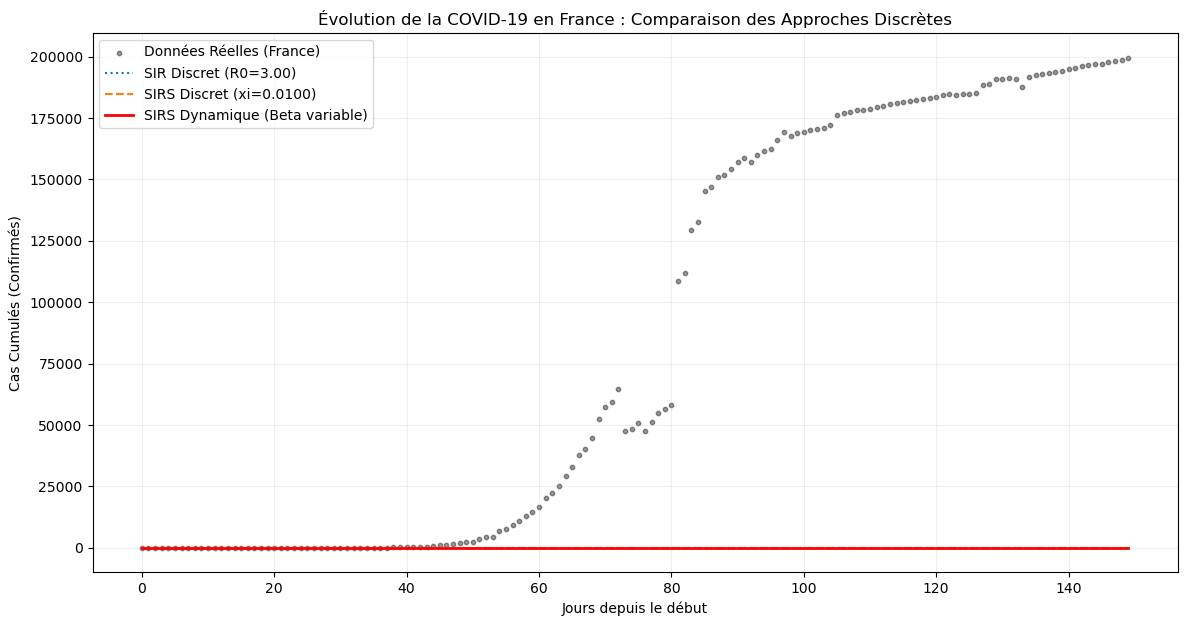

R0 moyen estimé (Modèle Dynamique) : 3.00


In [15]:
# 1. Ajuste SIR (Bounds: beta[0,5], gamma[0.01, 1])
popt_sir, _ = curve_fit(sir_discrete, x_days, y_real, p0=[0.3, 0.1], bounds=(0, [5, 1]))

# 2. Ajuste SIRS (Bounds: beta[0,5], gamma[0.01, 1], xi[0, 0.5])
popt_sirs, _ = curve_fit(sirs_discrete, x_days, y_real, p0=[0.3, 0.1, 0.01], bounds=(0, [5, 1, 0.5]))

# 3. Ajuste Dinâmico
initial_betas = [0.3] * num_nodes
lower_bounds = [0.01, 0] + [0] * num_nodes   # gamma, xi, betas
upper_bounds = [1.0, 0.5] + [5.0] * num_nodes
popt_dyn, _ = curve_fit(sirs_dynamic_discrete, x_days, y_real, 
                        p0=[0.1, 0.01, *initial_betas], 
                        bounds=(lower_bounds, upper_bounds))

# Geração das curvas
y_sir = sir_discrete(x_days, *popt_sir)
y_sirs = sirs_discrete(x_days, *popt_sirs)
y_dyn = sirs_dynamic_discrete(x_days, *popt_dyn)

# Visualização
plt.figure(figsize=(14, 7))
plt.scatter(x_days, y_real, label="Données Réelles (France)", color='black', alpha=0.4, s=10)
plt.plot(x_days, y_sir, label=f"SIR Discret (R0={popt_sir[0]/popt_sir[1]:.2f})", linestyle=':')
plt.plot(x_days, y_sirs, label=f"SIRS Discret (xi={popt_sirs[2]:.4f})", linestyle='--')
plt.plot(x_days, y_dyn, label="SIRS Dynamique (Beta variable)", color='red', linewidth=2)

plt.title("Évolution de la COVID-19 en France : Comparaison des Approches Discrètes")
plt.xlabel("Jours depuis le début")
plt.ylabel("Cas Cumulés (Confirmés)")
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

# Resultado do R0 Dinâmico
mean_beta = np.mean(popt_dyn[2:])
final_r0 = mean_beta / popt_dyn[0]
print(f"R0 moyen estimé (Modèle Dynamique) : {final_r0:.2f}")